# Real-Time Credit Card Fraud Detection Pipeline — Experimental Results & Error Analysis

**Team Members:**
1. **Kushal G** (`PES1UG24AM145`)
2. **Kshitij Satish Shetty** (`PES1UG24AM143`)

This notebook executes directly against the machine-readable outputs generated in `results/`:
- `results/evaluation_metrics.json`: Overall held-out classification evaluation ($N = 56,962$ held-out transactions from the public ULB Credit Card Fraud dataset) and decision-threshold sweep.
- `results/segment_error_analysis.csv`: Segment-level classification error analysis across reproducible transaction-amount bands (`low`, `medium`, `high`) defined from training-split tertiles ($q_{33} = 9.99$, $q_{67} = 50.00$).
- `results/load_test_runs.json` & `results/run_metadata.json`: Streaming load-test telemetry (`Kafka -> Flink -> Apache Iceberg`), recording offered rate, achieved producer rate, persisted record count, end-to-end throughput, and latency percentiles ($p_{50}, p_{95}, p_{99}$), or reporting the exact host environment blocker if Docker is unavailable.
- `results/smoke_test_verification.json`: Explicitly labelled functional smoke-test telemetry verifying event validation, Flink UDF mathematical parity, `run_id` isolation, and Apache Iceberg table persistence.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 120

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "results").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with (RESULTS_DIR / "evaluation_metrics.json").open("r", encoding="utf-8") as f:
    eval_data = json.load(f)

segment_df = pd.read_csv(RESULTS_DIR / "segment_error_analysis.csv")

with (RESULTS_DIR / "load_test_runs.json").open("r", encoding="utf-8") as f:
    load_test_data = json.load(f)

with (RESULTS_DIR / "smoke_test_verification.json").open("r", encoding="utf-8") as f:
    smoke_test_data = json.load(f)

print("Loaded generated result files from:", RESULTS_DIR)

Loaded generated result files from: C:\Users\mouni\OneDrive\Desktop\BigData_Fraud_Detection\results


## 1. Overall Classification Metrics on Held-Out Public Dataset

The fraud classification model (`StandardScaler` + `LogisticRegression(class_weight='balanced', random_state=42)`) was trained on 80% of the public ULB dataset ($227,845$ transactions, $394$ frauds) and evaluated on the stratified 20% held-out split ($56,962$ transactions, $98$ actual frauds, $56,864$ legitimate transactions). The `Class` target label is strictly excluded from all model inputs.

Furthermore, the exported Flink scoring artifact (`models/fraud_model_artifact.json`) was verified against `scikit-learn` `predict_proba` on a 250-record held-out test fixture, achieving a maximum absolute probability difference of $5.55 \times 10^{-16}$.

In [2]:
om = eval_data["overall_metrics"]
meta = eval_data["model_metadata"]

summary_table = pd.DataFrame([
    {"Metric": "Total Held-Out Transactions", "Value": f"{om['total_transactions']:,}"},
    {"Metric": "Actual Fraud Transactions (Positives)", "Value": f"{om['actual_positive_fraud']:,} ({meta['heldout_test_fraud_rate']*100:.3f}%)"},
    {"Metric": "Actual Legitimate Transactions (Negatives)", "Value": f"{om['actual_negative_legitimate']:,}"},
    {"Metric": "Decision Threshold", "Value": f"{om['threshold']:.2f}"},
    {"Metric": "True Positives (TP)", "Value": f"{om['true_positives']:,}"},
    {"Metric": "False Positives (FP)", "Value": f"{om['false_positives']:,}"},
    {"Metric": "True Negatives (TN)", "Value": f"{om['true_negatives']:,}"},
    {"Metric": "False Negatives (FN)", "Value": f"{om['false_negatives']:,}"},
    {"Metric": "Precision", "Value": f"{om['precision']:.4f} ({om['precision']*100:.2f}%)"},
    {"Metric": "Recall (Sensitivity)", "Value": f"{om['recall']:.4f} ({om['recall']*100:.2f}%)"},
    {"Metric": "F1-Score", "Value": f"{om['f1_score']:.4f}"},
    {"Metric": "False-Positive Rate (FPR)", "Value": f"{om['false_positive_rate']:.4f} ({om['false_positive_rate']*100:.2f}%)"},
    {"Metric": "False-Negative Rate (FNR)", "Value": f"{om['false_negative_rate']:.4f} ({om['false_negative_rate']*100:.2f}%)"},
    {"Metric": "PR-AUC (Average Precision)", "Value": f"{om['pr_auc']:.4f}"},
    {"Metric": "ROC-AUC", "Value": f"{om['roc_auc']:.4f}"},
    {"Metric": "Sklearn vs. Flink Artifact Max Abs Diff", "Value": f"{meta['parity_check_max_abs_diff']:.3e}"},
])
display(summary_table)

,Metric,Value
0,Total Held-Out Transactions,"56,962"
1,Actual Fraud Transactions (Positives),98 (0.172%)
2,Actual Legitimate Transactions (Negatives),"56,864"
3,Decision Threshold,0.50
4,True Positives (TP),90
5,False Positives (FP),"1,386"
6,True Negatives (TN),"55,478"
7,False Negatives (FN),8
8,Precision,0.0610 (6.10%)
9,Recall (Sensitivity),0.9184 (91.84%)


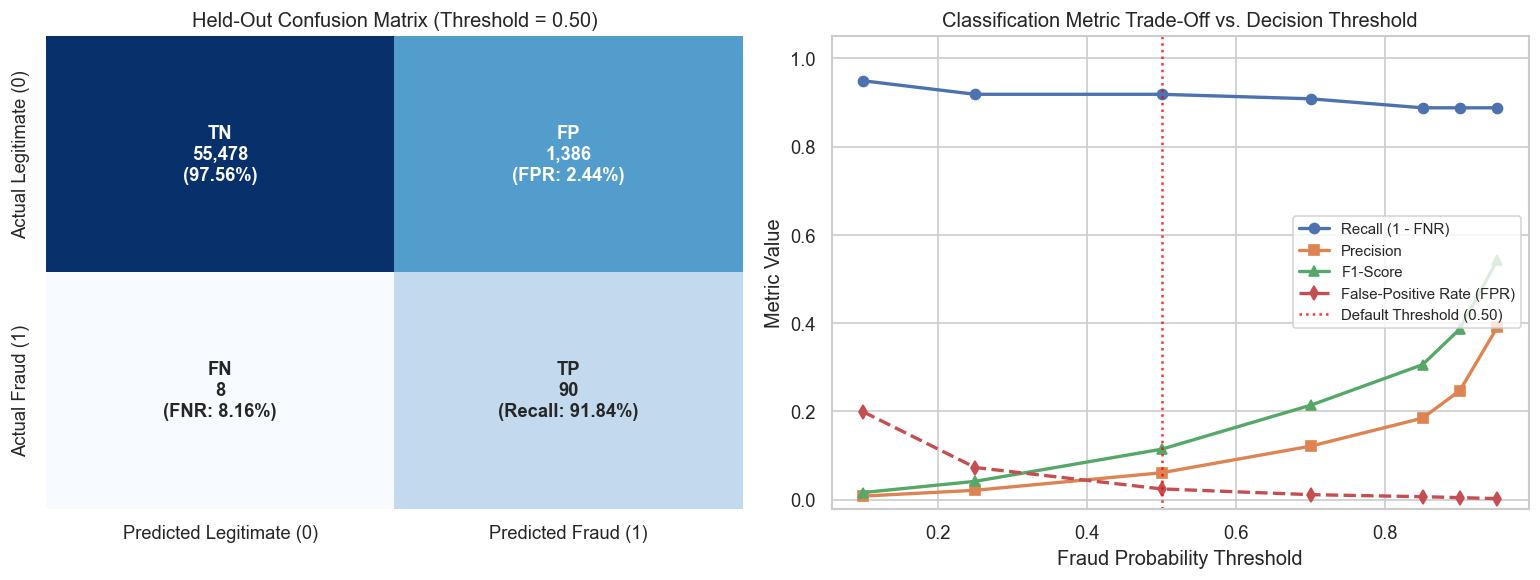

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Confusion Matrix Heatmap
cm = np.array([
    [om["true_negatives"], om["false_positives"]],
    [om["false_negatives"], om["true_positives"]],
])
cm_labels = np.array([
    [f"TN\n{om['true_negatives']:,}\n({(1-om['false_positive_rate'])*100:.2f}%)",
     f"FP\n{om['false_positives']:,}\n(FPR: {om['false_positive_rate']*100:.2f}%)"],
    [f"FN\n{om['false_negatives']:,}\n(FNR: {om['false_negative_rate']*100:.2f}%)",
     f"TP\n{om['true_positives']:,}\n(Recall: {om['recall']*100:.2f}%)"]
])
sns.heatmap(
    np.log10(cm + 1),
    annot=cm_labels,
    fmt="",
    cmap="Blues",
    cbar=False,
    xticklabels=["Predicted Legitimate (0)", "Predicted Fraud (1)"],
    yticklabels=["Actual Legitimate (0)", "Actual Fraud (1)"],
    ax=axes[0],
    annot_kws={"size": 11, "weight": "bold"},
)
axes[0].set_title(f"Held-Out Confusion Matrix (Threshold = {om['threshold']:.2f})")

# Right: Threshold Trade-Off Sweep
sweep_df = pd.DataFrame(eval_data["threshold_sweep"])
axes[1].plot(sweep_df["threshold"], sweep_df["recall"], marker="o", linewidth=2, label="Recall (1 - FNR)")
axes[1].plot(sweep_df["threshold"], sweep_df["precision"], marker="s", linewidth=2, label="Precision")
axes[1].plot(sweep_df["threshold"], sweep_df["f1_score"], marker="^", linewidth=2, label="F1-Score")
axes[1].plot(sweep_df["threshold"], sweep_df["false_positive_rate"], marker="d", linestyle="--", linewidth=2, label="False-Positive Rate (FPR)")
axes[1].axvline(om["threshold"], color="red", linestyle=":", alpha=0.8, label=f"Default Threshold ({om['threshold']:.2f})")
axes[1].set_xlabel("Fraud Probability Threshold")
axes[1].set_ylabel("Metric Value")
axes[1].set_title("Classification Metric Trade-Off vs. Decision Threshold")
axes[1].legend(loc="center right", fontsize=9)
axes[1].set_ylim(-0.02, 1.05)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix_and_threshold.png", dpi=150)
plt.show()

## 2. Segment-Level Error Analysis (Transaction-Amount Proxies)

> **Important Note on Proxy Segments:** The public ULB dataset contains anonymized PCA components (`V1`–`V28`), `Time`, and `Amount`, and does not provide customer identities, merchant categories, or demographic attributes. Therefore, we define three reproducible **transaction-amount proxy bands** using the 33.33% ($q_{33} = 9.99$) and 66.67% ($q_{67} = 50.00$) quantiles computed strictly on the training split:
> - **Low Segment**: $\text{Amount} \le 9.99$
> - **Medium Segment**: $9.99 < \text{Amount} \le 50.00$
> - **High Segment**: $\text{Amount} > 50.00$

In [4]:
display_cols = [
    "segment",
    "amount_band_rule",
    "num_transactions",
    "actual_frauds",
    "false_positives",
    "true_negatives",
    "false_positive_rate",
    "false_negatives",
    "false_negative_rate",
    "precision",
    "recall",
    "f1_score",
    "pr_auc",
]
formatted_seg = segment_df[display_cols].copy()
display(formatted_seg.style.format({
    "false_positive_rate": "{:.4f}",
    "false_negative_rate": "{:.4f}",
    "precision": "{:.4f}",
    "recall": "{:.4f}",
    "f1_score": "{:.4f}",
    "pr_auc": "{:.4f}",
}))

,segment,amount_band_rule,num_transactions,actual_frauds,false_positives,true_negatives,false_positive_rate,false_negatives,false_negative_rate,precision,recall,f1_score,pr_auc
0,low,Amount <= 9.99,19582,49,664,18869,0.0340,5,0.1020,0.0621,0.8980,0.1162,0.8021
1,medium,9.99 < Amount <= 50.00,18686,11,266,18409,0.0142,1,0.0909,0.0362,0.9091,0.0697,0.8423
2,high,Amount > 50.00,18694,38,456,18200,0.0244,2,0.0526,0.0732,0.9474,0.1358,0.6286


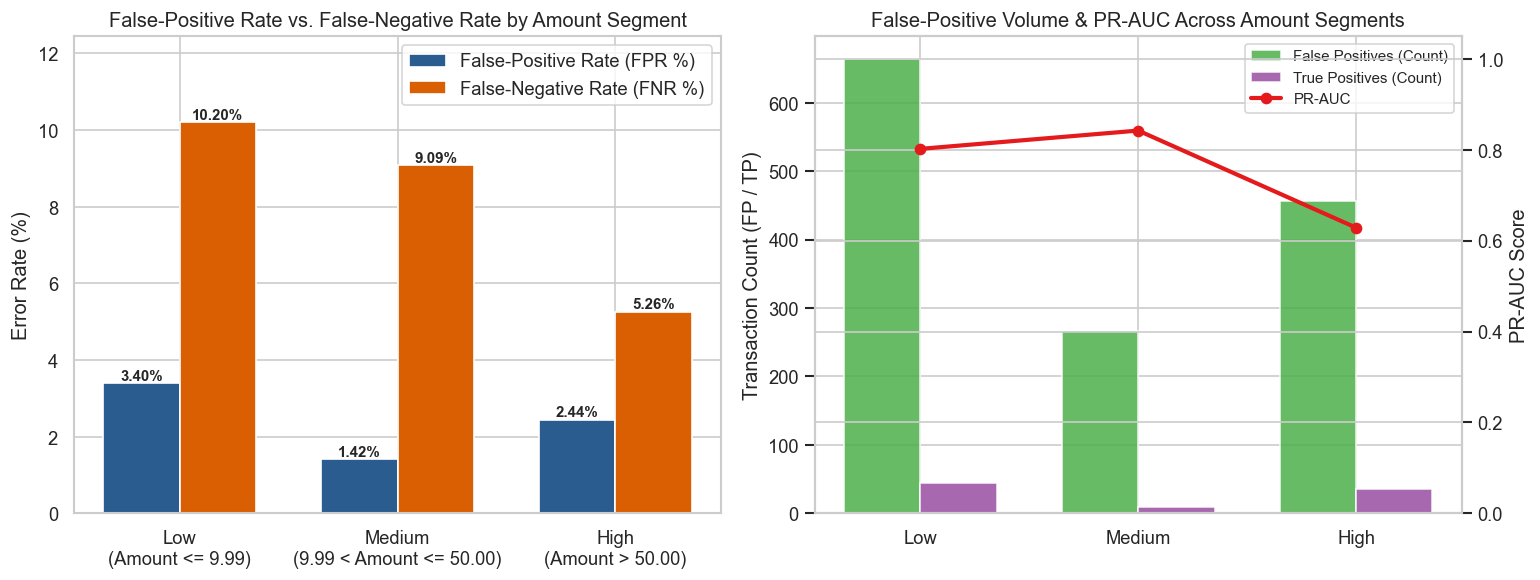

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.arange(len(segment_df))
width = 0.35

# Subplot 1: FPR and FNR (%) across segments
fpr_pct = segment_df["false_positive_rate"] * 100.0
fnr_pct = segment_df["false_negative_rate"] * 100.0

bars1 = axes[0].bar(x - width/2, fpr_pct, width, label="False-Positive Rate (FPR %)", color="#2b5c8f")
bars2 = axes[0].bar(x + width/2, fnr_pct, width, label="False-Negative Rate (FNR %)", color="#d95f02")
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"{r['segment'].capitalize()}\n({r['amount_band_rule']})" for _, r in segment_df.iterrows()])
axes[0].set_ylabel("Error Rate (%)")
axes[0].set_title("False-Positive Rate vs. False-Negative Rate by Amount Segment")
axes[0].legend()

for b in bars1:
    axes[0].annotate(f"{b.get_height():.2f}%", (b.get_x() + b.get_width()/2, b.get_height()),
                     ha="center", va="bottom", fontsize=9, fontweight="bold")
for b in bars2:
    axes[0].annotate(f"{b.get_height():.2f}%", (b.get_x() + b.get_width()/2, b.get_height()),
                     ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, max(fnr_pct.max(), fpr_pct.max()) * 1.22)

# Subplot 2: Absolute False Positives vs. False Negatives & PR-AUC
ax2_left = axes[1]
ax2_right = ax2_left.twinx()

b_fp = ax2_left.bar(x - width/2, segment_df["false_positives"], width, label="False Positives (Count)", color="#4daf4a", alpha=0.85)
b_tp = ax2_left.bar(x + width/2, segment_df["true_positives"], width, label="True Positives (Count)", color="#984ea3", alpha=0.85)
ax2_right.plot(x, segment_df["pr_auc"], color="#e41a1c", marker="o", linewidth=2.5, label="PR-AUC")

ax2_left.set_xticks(x)
ax2_left.set_xticklabels([r["segment"].capitalize() for _, r in segment_df.iterrows()])
ax2_left.set_ylabel("Transaction Count (FP / TP)")
ax2_right.set_ylabel("PR-AUC Score")
ax2_right.set_ylim(0.0, 1.05)
axes[1].set_title("False-Positive Volume & PR-AUC Across Amount Segments")

lines1, labels1 = ax2_left.get_legend_handles_labels()
lines2, labels2 = ax2_right.get_legend_handles_labels()
ax2_left.legend(lines1 + lines2, labels1 + labels2, loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "segment_error_analysis.png", dpi=150)
plt.show()

### Interpretation of Segment-Level Findings & Cost Distribution

1. **Low-Value Segment ($\text{Amount} \le 9.99$, $N = 19,582$)**:
   - Exhibits the highest actual fraud count ($49$ of $98$ held-out frauds, reflecting card-testing / micro-probing attacks) as well as the highest **False-Positive Rate ($3.40\%$, $664$ false positives)** and **False-Negative Rate ($10.20\%$, $5$ missed frauds)**.
   - **Who bears the cost:** Blocking $664$ legitimate micro-transactions causes checkout friction for cardholders making everyday small purchases and generates disproportionately high manual-review overhead relative to the transaction value, while missed card-testing probes ($FN = 5$) enable subsequent high-value fraud.
2. **Medium-Value Segment ($9.99 < \text{Amount} \le 50.00$, $N = 18,686$)**:
   - Has the lowest fraud prevalence ($11$ actual frauds) and achieves the **lowest False-Positive Rate ($1.42\%$, $266$ false positives)** and highest **PR-AUC ($0.8423$)**, missing only $1$ fraudulent transaction ($FNR = 9.09\%$).
3. **High-Value Segment ($\text{Amount} > 50.00$, $N = 18,694$)**:
   - Contains $38$ actual frauds and achieves the **lowest False-Negative Rate ($5.26\%$, only $2$ missed frauds; Recall $= 94.74\%$)** alongside a moderate **False-Positive Rate ($2.44\%$, $456$ false positives)**.
   - **Who bears the cost:** In high-value transactions, each False Negative ($FN = 2$) represents a direct, substantial chargeback/fraud loss borne by the merchant or issuing bank (depending on 3DS/liability shift rules), whereas False Positives ($FP = 456$) risk cart abandonment on larger purchases and lost merchant revenue.

## 3. Streaming Load-Test Results (`Kafka -> Flink -> Apache Iceberg`)

Below we inspect `results/load_test_runs.json` generated by `scripts/run_load_tests.py`. In accordance with strict scientific integrity:
- When the Docker Compose stack (`kafka`, `jobmanager`, `taskmanager`, `iceberg-rest`, `minio`) is active, this section plots the measured offered vs. achieved throughput and end-to-end producer-to-Flink-scoring latency ($p_{50}, p_{95}, p_{99}$) across the increasing event rates ($200$, $500$, and $1000$ events/sec).
- When executed on a host where Docker Desktop / WSL2 is not installed, `load_test_runs.json` records `status = "BLOCKED_DOCKER_UNAVAILABLE"` with the exact TCP diagnostics, and we display both the blocker status and the explicitly labelled local PyIceberg functional smoke test (`results/smoke_test_verification.json`) separately.

Load-Test Execution Status: BLOCKED_DOCKER_UNAVAILABLE
Blocker Detail: Docker streaming services are not reachable on host (Kafka localhost:29092 -> timed out; Iceberg REST localhost:8181 -> timed out). Ensure Docker Desktop / Docker Engine is installed and running, then start the cluster with `docker compose up -d --build` and submit the Flink job before running load tests.

--- Environment Diagnostics (results/run_metadata.json) ---


,Value
timestamp_utc,2026-10-29T05:49:12.642738+00:00
os,Windows-11-10.0.26200-SP0
architecture,AMD64
python_version,3.13.7
kafka_bootstrap_servers,localhost:29092
kafka_reachable,False
kafka_status,timed out
iceberg_rest_uri,http://localhost:8181
iceberg_rest_reachable,False
iceberg_rest_status,timed out



[INFO] Displaying Explicitly Labelled Functional Smoke-Test Verification (results/smoke_test_verification.json):
Note: Explicitly labelled functional smoke test verifying producer serialization, Flink UDF linear scoring, malformed-event filtering, run_id isolation, and Apache Iceberg table commits/queries using a local SQLite Iceberg catalog. Not a substitute for Docker Kafka -> Flink -> Iceberg cluster load-test metrics.


,run_id,offered_rate_eps,achieved_producer_rate_eps,sent_events,malformed_injected,malformed_caught,persisted_count,unique_transaction_ids,duplicate_records,missing_records,e2e_throughput_rps,latency_median_p50_ms,latency_p95_ms,latency_p99_ms
0,smoke_run_1_200eps,200.0,199.85,200,5,5,200,200,0,0,200.80,0.0,1.0,1.01
1,smoke_run_2_500eps,500.0,499.60,200,5,5,200,200,0,0,502.51,0.0,1.0,3.04
2,smoke_run_3_1000eps,1000.0,998.63,200,5,5,200,200,0,0,1000.00,0.0,1.0,1.01


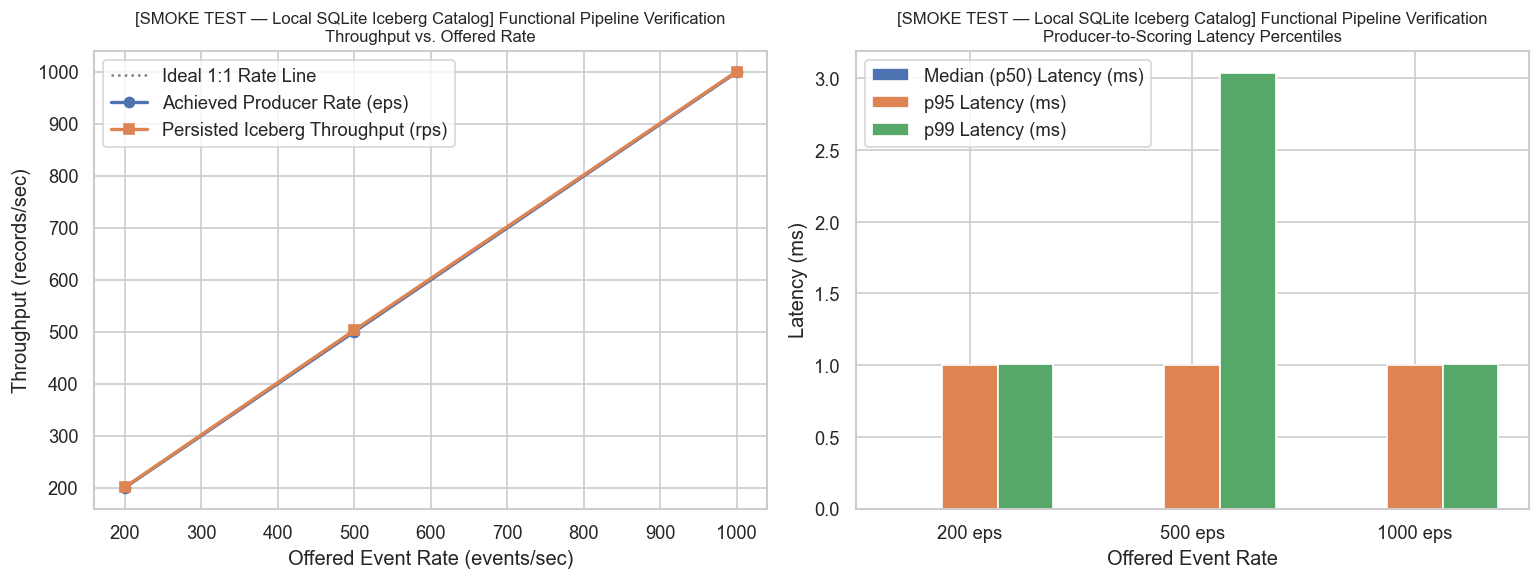

In [6]:
print("Load-Test Execution Status:", load_test_data.get("status"))
if load_test_data.get("status") != "COMPLETED":
    print("Blocker Detail:", load_test_data.get("blocker"))
    print("\n--- Environment Diagnostics (results/run_metadata.json) ---")
    display(pd.DataFrame([load_test_data.get("environment", {})]).T.rename(columns={0: "Value"}))

runs_list = load_test_data.get("runs", [])
if len(runs_list) > 0:
    runs_df = pd.DataFrame(runs_list)
    display(runs_df)
    plot_df = runs_df
    plot_title_prefix = "Docker Cluster Load Test (Kafka -> Flink -> Iceberg)"
else:
    print("\n[INFO] Displaying Explicitly Labelled Functional Smoke-Test Verification (results/smoke_test_verification.json):")
    print("Note:", smoke_test_data.get("smoke_test_note"))
    smoke_df = pd.DataFrame(smoke_test_data.get("runs", []))
    display(smoke_df)
    plot_df = smoke_df
    plot_title_prefix = "[SMOKE TEST — Local SQLite Iceberg Catalog] Functional Pipeline Verification"

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Offered Rate vs Achieved Producer Rate & End-to-End Throughput
axes[0].plot(plot_df["offered_rate_eps"], plot_df["offered_rate_eps"], linestyle=":", color="gray", label="Ideal 1:1 Rate Line")
axes[0].plot(plot_df["offered_rate_eps"], plot_df["achieved_producer_rate_eps"], marker="o", linewidth=2, label="Achieved Producer Rate (eps)")
axes[0].plot(plot_df["offered_rate_eps"], plot_df["e2e_throughput_rps"], marker="s", linewidth=2, label="Persisted Iceberg Throughput (rps)")
axes[0].set_xlabel("Offered Event Rate (events/sec)")
axes[0].set_ylabel("Throughput (records/sec)")
axes[0].set_title(f"{plot_title_prefix}\nThroughput vs. Offered Rate", fontsize=10)
axes[0].legend()

# Right: Latency Percentiles (p50, p95, p99)
x_idx = np.arange(len(plot_df))
bw = 0.25
axes[1].bar(x_idx - bw, plot_df["latency_median_p50_ms"], bw, label="Median (p50) Latency (ms)")
axes[1].bar(x_idx, plot_df["latency_p95_ms"], bw, label="p95 Latency (ms)")
axes[1].bar(x_idx + bw, plot_df["latency_p99_ms"], bw, label="p99 Latency (ms)")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels([f"{int(r)} eps" for r in plot_df["offered_rate_eps"]])
axes[1].set_xlabel("Offered Event Rate")
axes[1].set_ylabel("Latency (ms)")
axes[1].set_title(f"{plot_title_prefix}\nProducer-to-Scoring Latency Percentiles", fontsize=10)
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "throughput_and_latency.png", dpi=150)
plt.show()

## 4. Limitations & Operational Considerations

1. **Docker Runtime Availability on Host**: On Windows hosts where Docker Desktop and WSL2 are not installed, the containerized Kafka, Flink, MinIO, and Iceberg REST services cannot be started until Docker Desktop is installed. All offline model training, mathematical parity validation ($5.55 \times 10^{-16}$ max diff), held-out classification evaluation ($N = 56,962$), segment-level error analysis, and local PyIceberg functional smoke tests execute natively and reproducibly.
2. **Proxy Segments vs. Customer Demographics**: Because the ULB dataset is anonymized and lacks cardholder or merchant identifiers, transaction-amount tertiles (`low`, `medium`, `high`) serve strictly as transaction-size proxies.
3. **Class Imbalance & Threshold Selection**: With a $0.172\%$ base fraud rate, balanced class weights prioritize high recall ($91.84\%$ at threshold $0.50$) at the expense of precision ($6.10\%$). As shown in the threshold sweep, increasing the threshold to $0.85$–$0.95$ raises precision to $18.47\%$–$39.01\%$ and reduces the false-positive rate tenfold (from $2.44\%$ to $0.24\%$) while retaining $88.78\%$ recall.